<a href="https://colab.research.google.com/github/AfraazUlHaque/Non-Linear-SVM/blob/main/NLSVM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Training...
     pcost       dcost       gap    pres   dres
 0: -1.6891e+01 -5.4570e+01  5e+02  6e+00  5e-16
 1: -1.0756e+01 -4.5855e+01  4e+01  9e-16  6e-16
 2: -1.1748e+01 -1.5288e+01  4e+00  2e-16  5e-16
 3: -1.2788e+01 -1.3421e+01  6e-01  3e-16  5e-16
 4: -1.3027e+01 -1.3134e+01  1e-01  2e-16  5e-16
 5: -1.3061e+01 -1.3092e+01  3e-02  2e-16  4e-16
 6: -1.3074e+01 -1.3078e+01  4e-03  2e-16  5e-16
 7: -1.3076e+01 -1.3076e+01  1e-04  4e-16  5e-16
 8: -1.3076e+01 -1.3076e+01  3e-06  4e-16  5e-16
Optimal solution found.
Accuracy:  98.0
Time elapsed  0 m 0 s 158381 ms

Plotting decision boundary...


/tmp/ipykernel_1539/956781465.py:116: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  p[i] = s
/tmp/ipykernel_1539/956781465.py:144: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  z[i][j] = np.sign(s + b)


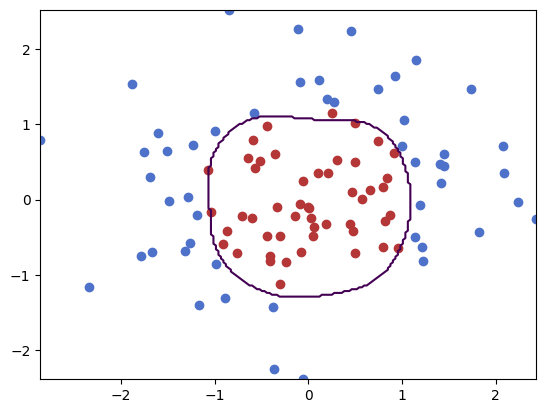

Time elapsed  0 m 2 s 910679 ms


In [1]:


from sklearn.datasets import make_gaussian_quantiles;
import matplotlib.pyplot as plt;
import numpy as np;
from cvxopt.solvers import qp;
import cvxopt.solvers;
from datetime import datetime

# Change parameters here
# TODO: poly_kernel vectorized is broken
C = 0.3;
poly_kernel = False
vectorized = True


# Langerian svm on data set with kernels
# This project uses very similar code to the linear-svm project but uses a nonlinear decision boundary

# Create training data with two features and binary classification
#X,y = make_classification(n_samples=100, n_redundant=0, class_sep=1.0, n_informative=1, n_features=2, n_clusters_per_class=1, random_state=345);
X,y = make_gaussian_quantiles(mean=None, cov=1.0, n_samples=100, n_features=2, n_classes=2, shuffle=True, random_state=5);

y[y==0] = -1

#Show a scatter plot of our data
plt.scatter(X[:,0][np.where(y == 1.0)], X[:,1][np.where(y == 1.0)], marker='o', c='#4e71c9');
plt.scatter(X[:,0][np.where(y == -1.0)], X[:,1][np.where(y == -1.0)], marker='o', c='#b53636');

m = X.shape[0];
y = np.reshape(y,(m,1));

# We must find the extrema of the function in the form 1/2*a'Pa-q'x subject to constraints

# Kernel function if poly is true will compute polynomial kernel otherwise gaussian

print("Training...")
startTime= datetime.now()

def kernel(a,b,d=20,poly=True,sigma=0.6):
    if (poly):
        return np.inner(a,b) ** d;
    else:
        return np.exp(-np.sum(np.sqrt(((a-b) ** 4))/sigma**2, axis=0))

def kernel_v(X,Y,d=20,poly=True,sigma=0.6,gram=False):
    if (poly):
        return np.einsum('ij,kj->ik',X,Y) ** d;
    elif (gram):
        X2 = X * X
        Y2 = Y * Y
        T = np.einsum('ik,jk',X2,6 * Y2) - np.einsum('ik,jk',X2*X,4*Y) - np.einsum('ik,jk',X ,4*Y2*Y)
        T += np.add.outer(np.einsum('ij,ij->i',X2,X2),np.einsum('ij,ij->i',Y2,Y2));
        return np.exp(-np.sqrt(np.maximum(0,T))/sigma ** 2);
    else:
        s = np.sqrt((np.subtract(X,Y) ** 4))
        return np.exp(-np.sum(s, axis=1)[:,None]/sigma**2)



# K must be a gram matrix which is all possible combinations of X and y

if (vectorized):
    K = kernel_v(X,X,poly=poly_kernel,gram=True);
else:
    K = np.array([kernel(X[i], X[j],poly=poly_kernel)
    for j in range(m)
    for i in range(m)]).reshape((m, m))



P = cvxopt.matrix(y.dot(y.T) * K);
q = cvxopt.matrix(-1.0 * np.ones((m)));

G = cvxopt.matrix(np.vstack((np.eye(m) * -1, np.eye(m))));
inner = np.hstack((np.zeros(m), np.ones(m) * C))
h = cvxopt.matrix(inner);

A = cvxopt.matrix(y.reshape(1,m).astype(float));
b = cvxopt.matrix(0.0);

solution = qp(P,q,G,h,A,b);

multipliers = np.ravel(solution['x']);

# Find the support vectors

has_positive_multiplier = multipliers > 1e-7;

sv_multipliers = multipliers[has_positive_multiplier];
sv_multipliers = sv_multipliers.reshape(sv_multipliers.shape[0],1)

support_vectors = X[has_positive_multiplier];
support_vectors_y = y[has_positive_multiplier];

#compute w and b so we can predict
# not sure if there is any way to vectorize this so I will just write a loop

b = 0.0;
# this will select only the rows with support vectors
ind = np.arange(len(multipliers))[has_positive_multiplier]

for n in range(len(sv_multipliers)):
    b += support_vectors_y[n]
    b -= np.sum(sv_multipliers[n] * support_vectors_y[n] * K[ind[n],has_positive_multiplier])
b /= len(multipliers);

# We do not have a weight vector and now we need to compute the nonlinear decision boundary


p = np.zeros(len(X))
for i in range(len(X)):
    s = 0
    for a, sv_y, sv in zip(sv_multipliers, support_vectors_y, support_vectors):
        s += a * sv_y * kernel(X[i], sv,poly=poly_kernel)
    p[i] = s

p = np.sign(p + b)

p = p.reshape(p.shape[0],1)

# TODO: Vectorize this method
#Plot decision boundary
print("Accuracy: ", np.mean(p == y) * 100)
# Time elapsed
timeElapsed=datetime.now()-startTime
print("Time elapsed ",int(timeElapsed.seconds/60), "m", timeElapsed.seconds - (60 * int(timeElapsed.seconds/60)), "s", timeElapsed.microseconds, "ms")
startTime= datetime.now()

print();
print("Plotting decision boundary...");

x_contour = np.linspace(np.min(X[:,0]),np.max(X[:,0]),200);
y_contour = np.linspace(np.min(X[:,1]),np.max(X[:,1]),200);
z = np.zeros((len(x_contour),len(y_contour)))

# do another one of these gram matrices or vectorized otherwise

if (vectorized):
    for i in range(len(x_contour)):
        for j in range(len(y_contour)):
            T = (sv_multipliers * support_vectors_y * kernel_v(np.array([x_contour[i],y_contour[j]]).reshape(2,1).T, support_vectors, poly=poly_kernel))
            s = np.sum(T, axis=0)
            z[i][j] = np.sign(s + b)
else:
    for i in range(len(x_contour)):
        for j in range(len(y_contour)):
            s = 0;
            for a, sv_y, sv in zip(sv_multipliers, support_vectors_y, support_vectors):
                s += a * sv_y * kernel(np.array([x_contour[i],y_contour[j]]), sv, poly=poly_kernel)
            z[i][j] = np.sign(s + b)


plt.contour(x_contour,y_contour,z.T,[0]);

plt.show();
timeElapsed=datetime.now()-startTime
print("Time elapsed ",int(timeElapsed.seconds/60), "m", timeElapsed.seconds - (60 * int(timeElapsed.seconds/60)), "s", timeElapsed.microseconds, "ms")

